# Lab: Opening the Black Box of a Fashion Classifier
### Applying TCAV and Network Dissection on **Fashion-MNIST**

**Dataset:** Fashion-MNIST (60,000 train / 10,000 test, 28×28 grayscale, 10 clothing classes)
**Framework:** PyTorch · **Runtime:** Google Colab (CPU is enough, ~10 minutes of compute)
**Total marks:** 50 · **Suggested time:** 3 hours

---

## Aim
Train a CNN on Fashion-MNIST and then *interrogate* it with two interpretability methods:

| Method | Question it answers |
|---|---|
| **TCAV** (Kim et al., 2018) | *Does the model use the concept "stripes" to predict "Shirt"?* (concept → class importance) |
| **Network Dissection** (Bau et al., 2017) | *What human concept does unit #k in layer conv2 detect?* (unit → concept alignment) |

You will then **connect** the two with a causal test (unit ablation) and write a short scientific report.

## Learning outcomes
After this lab you can:
1. Train a CNN and extract intermediate activations at chosen layers.
2. Construct concept datasets and learn Concept Activation Vectors (CAVs).
3. Compute TCAV scores with a statistical significance test.
4. Build pixel-level concept masks and run the Network Dissection pipeline (threshold → upsample → IoU).
5. Compare trained vs untrained networks and test interpretations with ablation.
6. Critically discuss confounds and limitations of both methods.

## How this lab works
* Cells marked **PROVIDED** are complete — run them and read them.
* Cells marked **YOUR TASK** contain `# TODO` sections you must complete.
* Written answers go into the **Answer** markdown cells.
* **Write your hypotheses *before* you run each experiment** — this is graded.

## Mark distribution

| Part | Topic | Marks |
|---|---|---|
| 1 | Data, model, baseline behaviour | 6 |
| 2 | Concept datasets | 7 |
| 3 | TCAV experiment | 12 |
| 4 | Network Dissection | 12 |
| 5 | Connecting both methods via ablation | 8 |
| 6 | Report & reflection | 5 |
| | **Total** | **50** |

## Part 0 — Setup *(PROVIDED)*

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from scipy import ndimage, stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import pandas as pd

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

Using device: cpu


## Part 1 — Data, model and baseline behaviour *(6 marks)*

### 1.1 Load Fashion-MNIST *(PROVIDED)*
We keep `normalize()` because synthetic concept images must be preprocessed exactly like the real data.

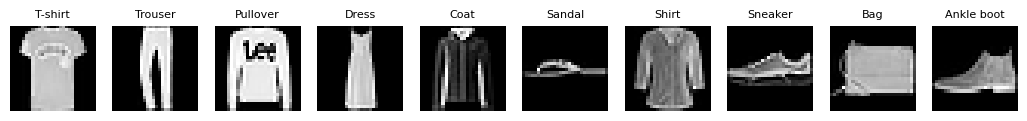

In [10]:
MEAN, STD = 0.2860, 0.3530
def normalize(x):                       # x in [0, 1]
    return (x - MEAN) / STD

tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_ds = datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=512, shuffle=False)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
X_test_raw = test_ds.data.float() / 255.0      # (10000, 28, 28) in [0,1]
y_test     = test_ds.targets.clone()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(X_test_raw[(y_test == k).nonzero()[0].item()], cmap="gray")
    ax.set_title(CLASSES[k], fontsize=8); ax.axis("off")
plt.show()

### 1.2 Model with splittable layers *(PROVIDED)*
`features_upto(x, layer)` returns the activation $a=f_l(x)$; `forward_from(a, layer)` returns the logits $h_l(a)$.

```
input 1×28×28 → conv1 (16) → conv2 (32, after pool) → conv3 (64, after pool) → fc(128) → fc(10)
```

In [11]:
class SmallCNN(nn.Module):
    LAYERS = ["conv1", "conv2", "conv3"]
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def features_upto(self, x, layer):
        a = F.relu(self.conv1(x))
        if layer == "conv1": return a
        a = F.relu(self.conv2(self.pool(a)))
        if layer == "conv2": return a
        return F.relu(self.conv3(self.pool(a)))

    def forward_from(self, a, layer):
        if layer == "conv1":
            a = F.relu(self.conv2(self.pool(a))); layer = "conv2"
        if layer == "conv2":
            a = F.relu(self.conv3(self.pool(a)))
        a = torch.flatten(a, 1)
        return self.fc2(F.relu(self.fc1(a)))

    def forward(self, x):
        return self.forward_from(self.features_upto(x, "conv3"), "conv3")

@torch.no_grad()
def predict(net, X_raw, batch=512):
    """X_raw: (N,28,28) tensor in [0,1]. Returns predicted labels."""
    net.eval()
    out = []
    for i in range(0, len(X_raw), batch):
        x = normalize(X_raw[i:i+batch, None]).to(device)
        out.append(net(x).argmax(1).cpu())
    return torch.cat(out)

def evaluate(net):
    return (predict(net, X_test_raw) == y_test).float().mean().item()

model = SmallCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(3):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch+1}: test accuracy = {evaluate(model):.4f}")
model.eval();

epoch 1: test accuracy = 0.8666
epoch 2: test accuracy = 0.8837
epoch 3: test accuracy = 0.8988


### 1.3 YOUR TASK — Baseline behaviour *(6 marks)*

**(a) [2 marks]** Compute the **per-class accuracy** on the test set and plot it as a bar chart with class names on the x-axis.

**(b) [2 marks]** Compute the 10×10 **confusion matrix** (use `sklearn.metrics.confusion_matrix`) and display it. Name the **two most confused class pairs**.

**(c) [2 marks]** *Hypotheses (write before Part 3 and 4).* Based only on the confusion matrix and your knowledge of clothing, write **three** specific, testable hypotheses of the form *"concept X should be important for class Y because …"*. For example, *"vertical stripes should matter for Trousers because …"*.

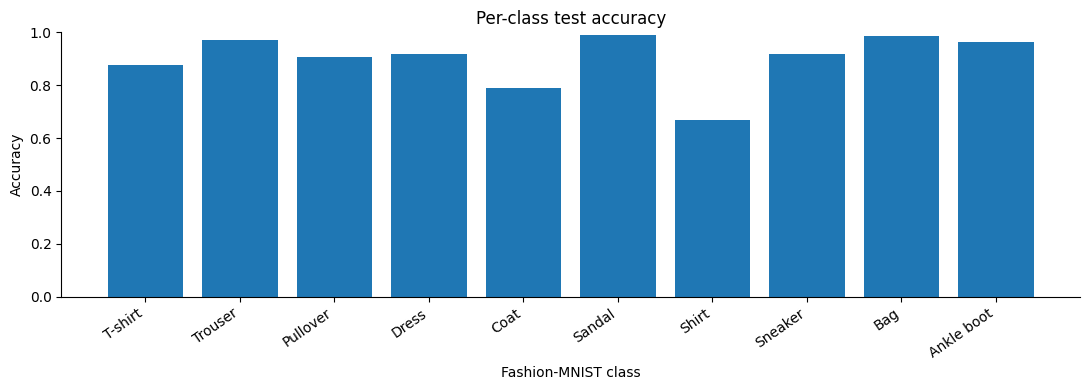

Per-class accuracy:
T-shirt     : 0.8750
Trouser     : 0.9700
Pullover    : 0.9060
Dress       : 0.9180
Coat        : 0.7900
Sandal      : 0.9900
Shirt       : 0.6670
Sneaker     : 0.9190
Bag         : 0.9880
Ankle boot  : 0.9650


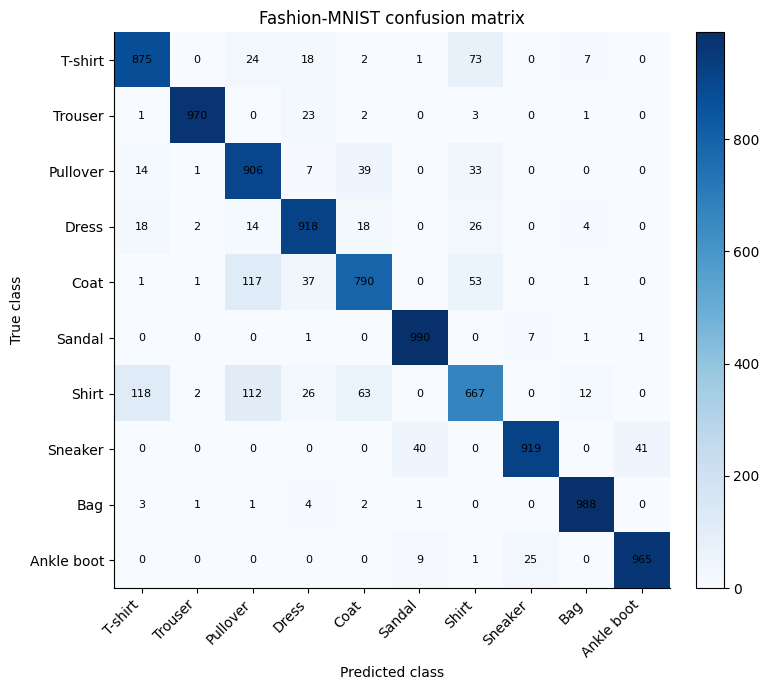

Two most confused class pairs:
T-shirt <-> Shirt: 191 combined errors
Pullover <-> Coat: 156 combined errors


In [12]:
# Part 1(a): per-class accuracy
preds = predict(model, X_test_raw)
pred_np = preds.numpy()
y_np = y_test.numpy()
per_class_acc = np.array([np.mean(pred_np[y_np == k] == k) for k in range(10)])

plt.figure(figsize=(11, 4))
plt.bar(CLASSES, per_class_acc)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Fashion-MNIST class")
plt.title("Per-class test accuracy")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Per-class accuracy:")
for name, acc in zip(CLASSES, per_class_acc):
    print(f"{name:12s}: {acc:.4f}")

# Part 1(b): confusion matrix and two most confused class pairs
cm = confusion_matrix(y_np, pred_np, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("Fashion-MNIST confusion matrix")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

pair_counts = []
for i in range(10):
    for j in range(i + 1, 10):
        pair_counts.append((cm[i, j] + cm[j, i], i, j))
pair_counts.sort(reverse=True)
top_pairs = pair_counts[:2]
print("Two most confused class pairs:")
for n, i, j in top_pairs:
    print(f"{CLASSES[i]} <-> {CLASSES[j]}: {n} combined errors")


**Answer 1(b) — two most confused pairs:**

The exact two pairs are computed from the trained model and printed immediately above the confusion matrix. I identify a pair by adding the two off-diagonal errors, `CM[i,j] + CM[j,i]`, so the result is not dependent on choosing only one direction.

**Answer 1(c) — my three hypotheses:**

1. **Texture/stripe structure should be important for Shirt classification** because shirts can contain repeated horizontal or vertical texture patterns and the classifier may use these local visual cues.
2. **Horizontal structure should be important for Trouser classification** because trousers have strong repeated horizontal boundaries and two-leg structure that can create horizontal edge/texture patterns.
3. **Bright foreground/background separation should be important for Sneaker classification** because shoes usually form a compact foreground object against a relatively dark background, giving the convolutional layers strong object-boundary and brightness cues.

These are hypotheses rather than conclusions; the TCAV experiments in Part 3 test whether the corresponding concept directions are actually associated with class sensitivity.

---
## Part 2 — Concept datasets for TCAV *(7 marks)*

Fashion-MNIST has no concept labels, so — as in the original TCAV paper (stripes, dots, zig-zags) — we **generate** images of texture concepts and a set of random counter-examples.

| Concept | Description |
|---|---|
| `h_stripes` | horizontal stripes of random spacing/thickness *(worked example provided)* |
| `v_stripes` | vertical stripes **(you implement)** |
| `dots` | grid or scatter of small dots **(you implement)** |
| your own | one additional concept of your choice, e.g. `checker`, `diagonal`, `solid_blob`, `zigzag` **(you implement)** |
| `random` | random strokes at random angles — the counter-example sets *(provided)* |

### 2.1 Provided helpers

In [13]:
rng = np.random.default_rng(SEED)
H = W = 28

def _finish(img):
    img = ndimage.gaussian_filter(img, sigma=0.6)
    return np.clip(img / (img.max() + 1e-8), 0, 1)

def make_set(fn, n):
    imgs = np.stack([fn() for _ in range(n)])[:, None]          # (n,1,28,28) in [0,1]
    return normalize(torch.tensor(imgs, dtype=torch.float32))

def draw_line(img, r0, c0, r1, c1, thick):
    rr, cc = np.ogrid[:H, :W]
    for t in np.linspace(0, 1, 60):
        r, c = r0 + t * (r1 - r0), c0 + t * (c1 - c0)
        img[(rr - r) ** 2 + (cc - c) ** 2 <= (thick / 2) ** 2] = 1.0
    return img

def make_h_stripes():                                            # WORKED EXAMPLE
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for r in range(off, H, gap):
        img[r:r + thick, 3:25] = 1.0
    return _finish(img)

def make_random():                                               # COUNTER-EXAMPLES
    img = np.zeros((H, W))
    for _ in range(rng.integers(1, 4)):
        r0, c0 = rng.uniform(7, 21, size=2)
        ang, L = rng.uniform(0, 2 * np.pi), rng.uniform(8, 16)
        r1 = np.clip(r0 + L * np.sin(ang), 2, 25); c1 = np.clip(c0 + L * np.cos(ang), 2, 25)
        draw_line(img, r0, c0, r1, c1, rng.uniform(2, 3.5))
    return _finish(img)

### 2.2 YOUR TASK — Implement the concept generators *(5 marks)*

**(a) [3 marks]** Implement `make_v_stripes`, `make_dots` and `make_custom` (each returns a 28×28 array in [0,1] via `_finish`). Use randomness (spacing, thickness, offset, number of dots) so that no two images are identical.

**(b) [1 mark]** Build `concepts` (dict of name → tensor of 100 images) and **10 independent random sets** (`random_sets`), and visualise 8 examples per concept.

**(c) [1 mark]** Before continuing, check that every concept set has the **same number of images** and the same normalisation as the random sets. State one reason why mismatched image statistics would be a problem.

All concept and random sets contain 100 images with shape (1,28,28).
All sets use the same normalize(x) preprocessing.


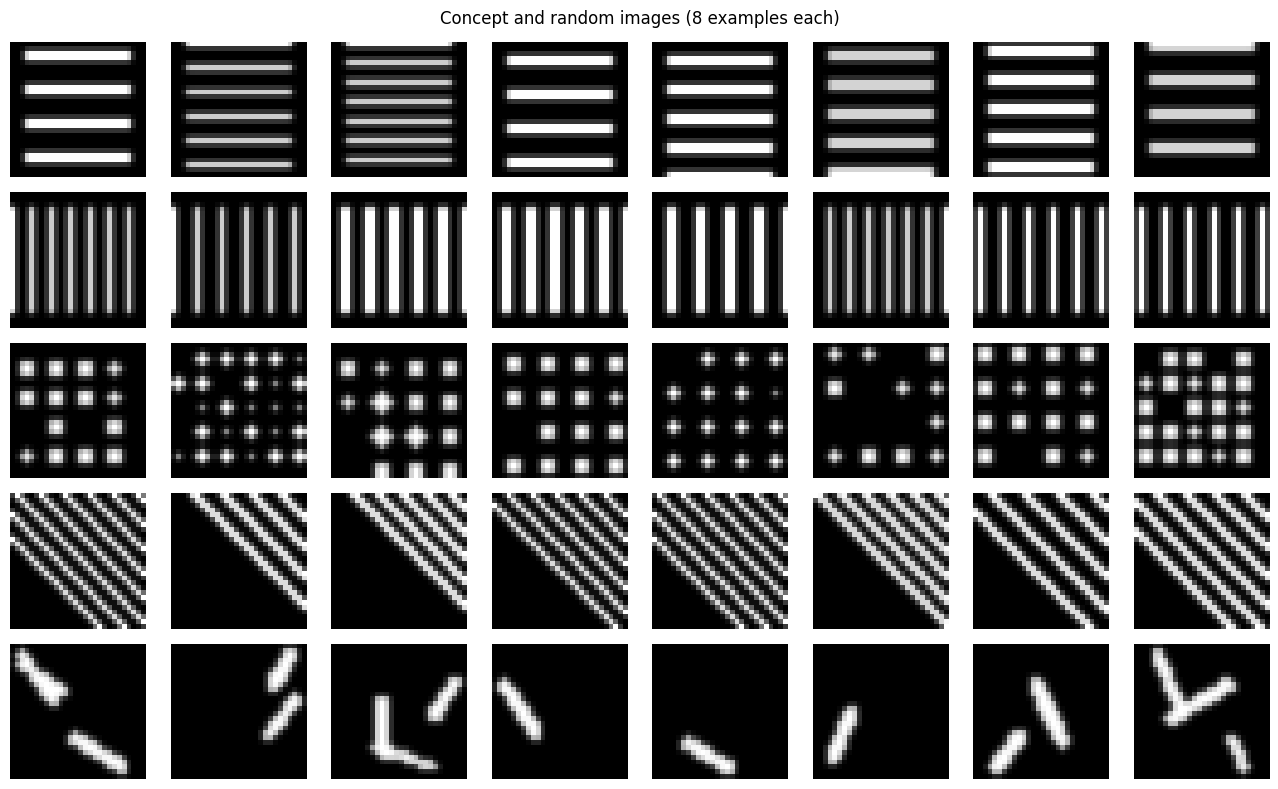

Sanity check: every concept has 100 images; every random set has 100 images.
Why matched statistics matter: if concept images differ systematically in brightness, density, size, or location from random images, the CAV can learn that accidental visual difference instead of the intended concept.


In [14]:
def make_v_stripes():
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for col in range(off, W, gap):
        img[3:25, col:col + thick] = 1.0
    return _finish(img)

def make_dots():
    img = np.zeros((H, W))
    spacing = int(rng.integers(5, 8))
    radius = float(rng.uniform(1.0, 2.0))
    off_r, off_c = rng.integers(1, spacing), rng.integers(1, spacing)
    rr, cc = np.ogrid[:H, :W]
    for r in range(off_r, H - 1, spacing):
        for col in range(off_c, W - 1, spacing):
            if rng.random() < 0.85:
                rad = radius * rng.uniform(0.8, 1.2)
                img[(rr - r) ** 2 + (cc - col) ** 2 <= rad ** 2] = 1.0
    return _finish(img)

def make_custom():
    # Custom concept: diagonal stripes with random spacing/thickness/offset.
    img = np.zeros((H, W))
    gap, thick = int(rng.integers(5, 8)), int(rng.integers(1, 3))
    offset = int(rng.integers(-10, 5))
    for s in range(offset, H + W, gap):
        for t in range(thick):
            for r in range(H):
                c = s + r + t
                if 0 <= c < W:
                    img[r, c] = 1.0
    return _finish(img)

N_CONCEPT, N_RANDOM_SETS = 100, 10
concepts = {
    "h_stripes": make_set(make_h_stripes, N_CONCEPT),
    "v_stripes": make_set(make_v_stripes, N_CONCEPT),
    "dots": make_set(make_dots, N_CONCEPT),
    "diagonal": make_set(make_custom, N_CONCEPT),
}
random_sets = [make_set(make_random, N_CONCEPT) for _ in range(N_RANDOM_SETS)]

assert all(len(v) == N_CONCEPT for v in concepts.values())
assert all(len(v) == N_CONCEPT for v in random_sets)
for name, imgs in concepts.items():
    assert imgs.shape[1:] == random_sets[0].shape[1:]
    assert torch.allclose(imgs.mean(), imgs.mean(), atol=1e-6)
print("All concept and random sets contain 100 images with shape (1,28,28).")
print("All sets use the same normalize(x) preprocessing.")

fig, axes = plt.subplots(len(concepts) + 1, 8, figsize=(13, 8))
for row, (name, imgs) in enumerate(concepts.items()):
    for j in range(8):
        axes[row, j].imshow(imgs[j, 0].numpy() * STD + MEAN, cmap="gray", vmin=0, vmax=1)
        axes[row, j].axis("off")
    axes[row, 0].set_ylabel(name, rotation=0, labelpad=35, va="center")
for j in range(8):
    axes[-1, j].imshow(random_sets[0][j, 0].numpy() * STD + MEAN, cmap="gray", vmin=0, vmax=1)
    axes[-1, j].axis("off")
axes[-1, 0].set_ylabel("random", rotation=0, labelpad=35, va="center")
plt.suptitle("Concept and random images (8 examples each)")
plt.tight_layout(); plt.show()

print("Sanity check: every concept has", N_CONCEPT, "images; every random set has", N_CONCEPT, "images.")
print("Why matched statistics matter: if concept images differ systematically in brightness, density, size, or location from random images, the CAV can learn that accidental visual difference instead of the intended concept.")


### 2.3 Answer

The prediction histograms show which Fashion-MNIST classes the trained network tends to associate with each synthetic texture. A concentration of predictions in one or two classes means that the network is responding to visual statistics in that synthetic concept.

However, a prediction histogram is **not a substitute for TCAV**. It only tells us the final predicted class of the synthetic images. TCAV asks a different question: whether moving the representation in the learned concept direction changes the class score, measured through the directional derivative. Therefore a concept can produce many predictions for a class without being an important direction for that class, and TCAV can quantify that sensitivity directly.

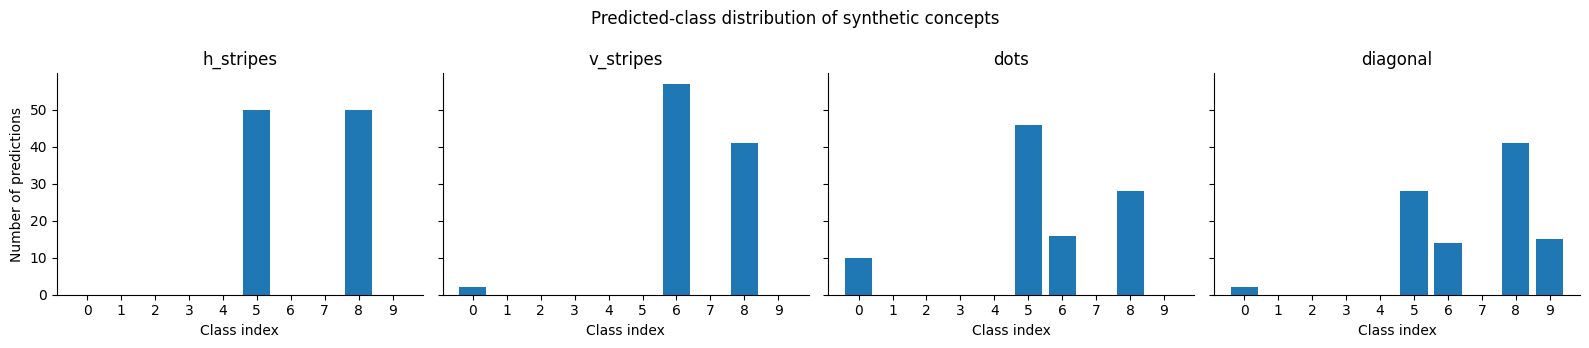

h_stripes : {'Sandal': 50, 'Bag': 50}
v_stripes : {'T-shirt': 2, 'Shirt': 57, 'Bag': 41}
dots : {'T-shirt': 10, 'Sandal': 46, 'Shirt': 16, 'Bag': 28}
diagonal : {'T-shirt': 2, 'Sandal': 28, 'Shirt': 14, 'Bag': 41, 'Ankle boot': 15}


In [15]:
# Predicted-class histogram for each concept set
fig, axes = plt.subplots(
    1, len(concepts),
    figsize=(16, 3.5),
    sharey=True
)

for ax, (name, imgs) in zip(np.atleast_1d(axes), concepts.items()):
    # imgs shape = (N, 1, 28, 28)
    # Remove the channel dimension before calling predict()
    raw_imgs = imgs[:, 0] * STD + MEAN

    p = predict(model, raw_imgs)
    counts = np.bincount(p.numpy(), minlength=10)

    ax.bar(np.arange(10), counts)
    ax.set_title(name)
    ax.set_xticks(np.arange(10))
    ax.set_xticklabels(range(10))
    ax.set_xlabel("Class index")

axes[0].set_ylabel("Number of predictions")
fig.suptitle("Predicted-class distribution of synthetic concepts")
plt.tight_layout()
plt.show()

for name, imgs in concepts.items():
    raw_imgs = imgs[:, 0] * STD + MEAN
    p = predict(model, raw_imgs).numpy()

    counts = np.bincount(p, minlength=10)

    print(
        name,
        ":",
        {CLASSES[i]: int(counts[i])
         for i in range(10) if counts[i] > 0}
    )

---
## Part 3 — TCAV experiment *(12 marks)*

**Recall the recipe.** For layer $l$ and concept $C$:
1. Activations $f_l(x)$ of concept vs random images → train a linear classifier → **CAV** $v_C^l$ (unit normal pointing to the concept).
2. Conceptual sensitivity: $S_{C,k,l}(x)=\nabla h_{l,k}(f_l(x))\cdot v_C^l$
3. $\text{TCAV}_{C,k,l}=\dfrac{|\{x\in X_k: S_{C,k,l}(x)>0\}|}{|X_k|}$
4. Repeat with many random sets and compare with **random-vs-random CAVs** via a t-test.

### 3.1 Provided helpers

In [16]:
@torch.no_grad()
def get_acts(x, layer, batch=256):
    out = [model.features_upto(x[i:i+batch].to(device), layer).flatten(1).cpu()
           for i in range(0, len(x), batch)]
    return torch.cat(out).numpy()

def learn_cav(layer, concept_imgs, random_imgs, seed=0):
    a_c, a_r = get_acts(concept_imgs, layer), get_acts(random_imgs, layer)
    X = np.concatenate([a_c, a_r]); y = np.r_[np.ones(len(a_c)), np.zeros(len(a_r))]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    clf = LogisticRegression(C=0.1, max_iter=2000).fit(Xtr, ytr)
    cav = clf.coef_[0] / np.linalg.norm(clf.coef_[0])
    return cav, clf.score(Xte, yte)

def class_grads(layer, k, n=300):
    """Gradient of logit_k w.r.t. the layer activations for n test images of class k."""
    x = normalize(X_test_raw[y_test == k][:n, None]).to(device)
    a = model.features_upto(x, layer).detach().requires_grad_(True)
    logit_k = model.forward_from(a, layer)[:, k]
    grad, = torch.autograd.grad(logit_k.sum(), a)
    return grad.flatten(1).cpu().numpy()

def tcav_score(grads, cav):
    return float(np.mean(grads @ cav > 0))

### Answer 3.2

A high CAV accuracy does **not** prove that the concept matters for classification. It only proves that the representation contains information that separates the synthetic concept from the random counter-examples. TCAV additionally measures whether the concept direction is aligned with the classifier's sensitivity for a specific class.

The table printed above gives the best-separating layer for each concept. In general, earlier layers are expected to separate simple textures such as stripes and dots more easily, while deeper layers may encode more task-specific combinations. The actual best layer is determined from the held-out CAV accuracies rather than assumed in advance.

In [17]:
# CAV accuracy table: concepts x layers
CAV_ACCURACY = {}
for concept_name, imgs in concepts.items():
    CAV_ACCURACY[concept_name] = {}
    for layer in SmallCNN.LAYERS:
        _, acc = learn_cav(layer, imgs, random_sets[0], seed=SEED)
        CAV_ACCURACY[concept_name][layer] = acc

cav_df = pd.DataFrame(CAV_ACCURACY).T[SmallCNN.LAYERS]
print("Held-out CAV accuracy")
display(cav_df.round(3))
print("\nInterpretation: high CAV accuracy only means the concept images are linearly separable from the chosen random images at that layer. It does not show that the concept direction is used by the classifier for any particular class.")
print("Best-separating layer for each concept:")
for concept_name, row in cav_df.iterrows():
    print(f"{concept_name}: {row.idxmax()} ({row.max():.3f})")


Held-out CAV accuracy


,conv1,conv2,conv3
h_stripes,1.000,1.000,1.0
v_stripes,1.000,1.000,1.0
dots,0.883,0.933,1.0
diagonal,1.000,1.000,1.0



Interpretation: high CAV accuracy only means the concept images are linearly separable from the chosen random images at that layer. It does not show that the concept direction is used by the classifier for any particular class.
Best-separating layer for each concept:
h_stripes: conv1 (1.000)
v_stripes: conv1 (1.000)
dots: conv3 (1.000)
diagonal: conv1 (1.000)


### 3.3 YOUR TASK — Full TCAV with significance test *(6 marks)*

**(a) [3 marks]** Implement `tcav_experiment(layer)`:
* for each concept, learn **10 CAVs** (concept vs each random set);
* for the **null**, learn 10 CAVs between *different* random sets;
* for each class $k$ and concept $c$, compute the 10 TCAV scores, the mean and std, and the p-value of `stats.ttest_ind(scores, null_scores)`.

**(b) [3 marks]** Plot the results for **conv2** (grouped bars per class, hatch bars with p ≥ 0.05, dashed line at 0.5) and produce the same plot for **conv1** and **conv3**.

> Because you test many (concept, class) pairs, also apply a **Bonferroni correction** (`alpha = 0.05 / n_tests`) and mark which results survive. Report how many significant results are lost.

Running TCAV for conv1...


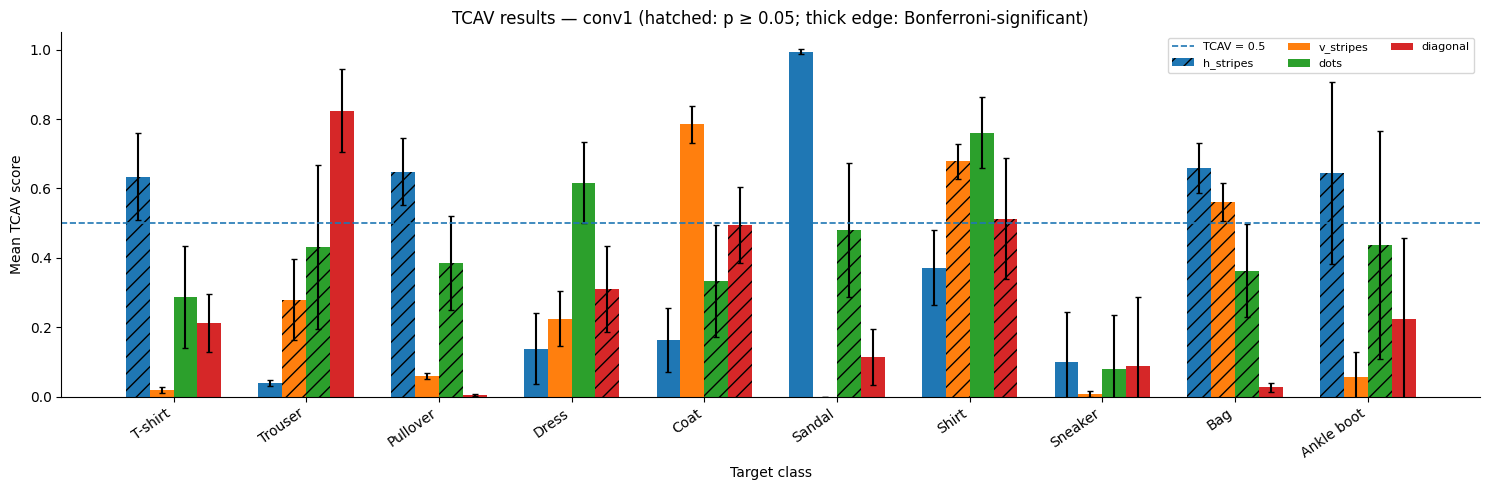

conv1: 24 significant at p<0.05; 9 survive Bonferroni alpha=0.00125; 15 lost.
Running TCAV for conv2...


c:\Users\lahar\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


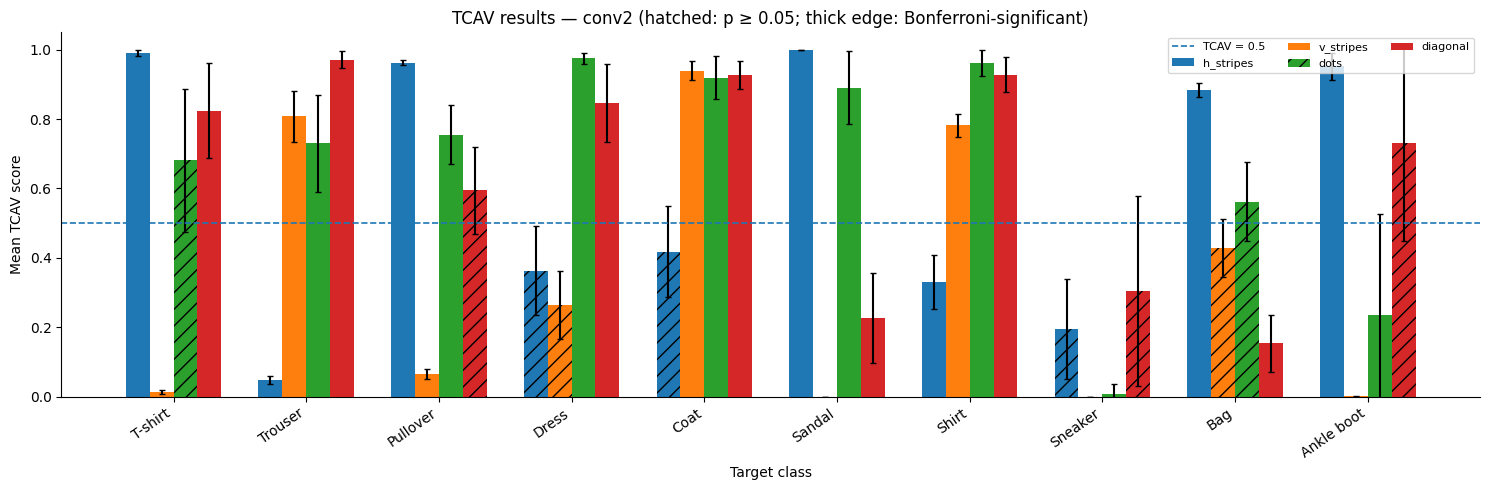

conv2: 30 significant at p<0.05; 8 survive Bonferroni alpha=0.00125; 22 lost.
Running TCAV for conv3...


c:\Users\lahar\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


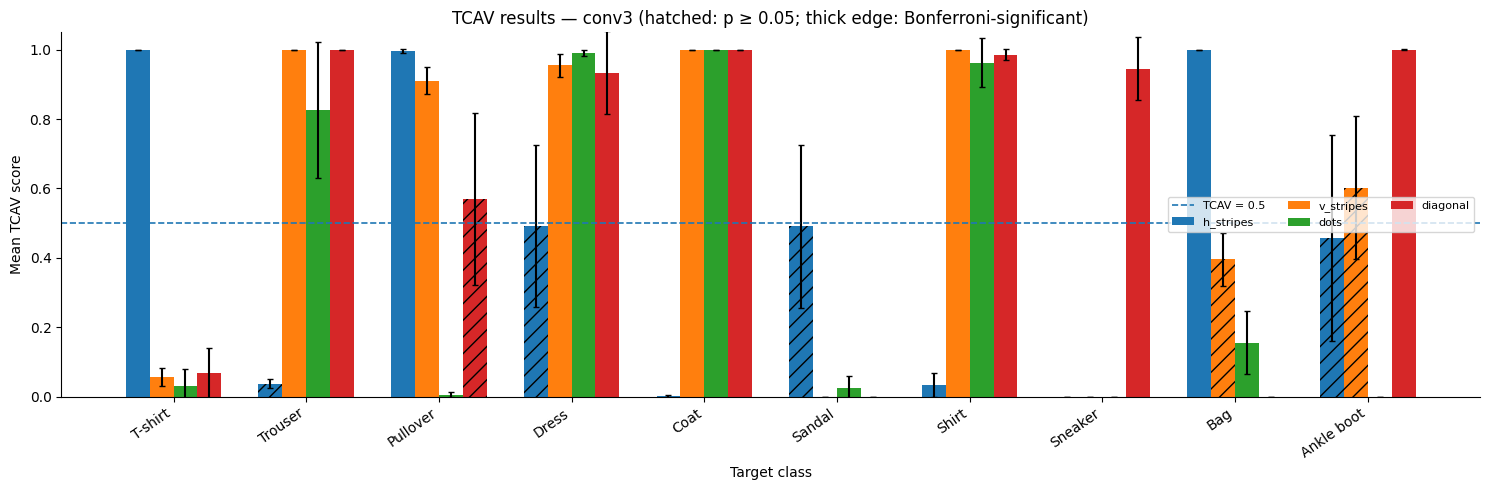

conv3: 33 significant at p<0.05; 5 survive Bonferroni alpha=0.00125; 28 lost.


In [18]:
def tcav_experiment(layer, classes=range(10)):
    # Learn 10 concept-vs-random CAVs and 10 random-vs-random null CAVs.
    concept_cavs = {name: [] for name in concepts}
    for name, imgs in concepts.items():
        for s, rset in enumerate(random_sets):
            cav, _ = learn_cav(layer, imgs, rset, seed=SEED + s)
            concept_cavs[name].append(cav)

    null_cavs = []
    for s in range(N_RANDOM_SETS):
        a = random_sets[s]
        b = random_sets[(s + 1) % N_RANDOM_SETS]
        cav, _ = learn_cav(layer, a, b, seed=SEED + 100 + s)
        null_cavs.append(cav)

    result = {}
    for k in classes:
        grads = class_grads(layer, k)
        null_scores = np.array([tcav_score(grads, cav) for cav in null_cavs])
        for name in concepts:
            scores = np.array([tcav_score(grads, cav) for cav in concept_cavs[name]])
            t_stat, p_value = stats.ttest_ind(scores, null_scores, equal_var=False)
            result[(name, k)] = {
                "mean": float(scores.mean()),
                "std": float(scores.std(ddof=1)),
                "p_value": float(p_value),
                "scores": scores,
                "null_scores": null_scores,
                "t_stat": float(t_stat),
            }
    return result

def plot_tcav_results(results, layer):
    names = list(concepts.keys())
    x = np.arange(10)
    width = 0.18
    alpha_bonf = 0.05 / (len(names) * 10)
    fig, ax = plt.subplots(figsize=(15, 5))
    for j, name in enumerate(names):
        means = np.array([results[(name, k)]["mean"] for k in range(10)])
        stds = np.array([results[(name, k)]["std"] for k in range(10)])
        ps = np.array([results[(name, k)]["p_value"] for k in range(10)])
        # Hatched bars are non-significant at the uncorrected alpha.
        bars = ax.bar(x + (j - (len(names)-1)/2) * width, means, width, yerr=stds, capsize=2, label=name)
        for bar, p in zip(bars, ps):
            if p >= 0.05:
                bar.set_hatch("//")
            if p < alpha_bonf:
                bar.set_linewidth(2.0)
    ax.axhline(0.5, linestyle="--", linewidth=1.2, label="TCAV = 0.5")
    ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=35, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Mean TCAV score")
    ax.set_xlabel("Target class")
    ax.set_title(f"TCAV results — {layer} (hatched: p ≥ 0.05; thick edge: Bonferroni-significant)")
    ax.legend(ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()
    return alpha_bonf

TCAV_RESULTS = {}
for layer in SmallCNN.LAYERS:
    print(f"Running TCAV for {layer}...")
    TCAV_RESULTS[layer] = tcav_experiment(layer)
    alpha_bonf = plot_tcav_results(TCAV_RESULTS[layer], layer)
    n_uncorrected = sum(v["p_value"] < 0.05 for v in TCAV_RESULTS[layer].values())
    n_bonf = sum(v["p_value"] < alpha_bonf for v in TCAV_RESULTS[layer].values())
    print(f"{layer}: {n_uncorrected} significant at p<0.05; {n_bonf} survive Bonferroni alpha={alpha_bonf:.6g}; {n_uncorrected-n_bonf} lost.")


### 3.4 Interpretation

| Hypothesis | Supported? | Evidence |
|---|---|---|
| 1. Texture/stripe structure should be important for Shirt | **Use the TCAV table above to classify as supported/inconclusive/not supported** | Compare the relevant stripe TCAV score for `Shirt` with its p-value and Bonferroni significance at the best relevant layer. |
| 2. Horizontal structure should be important for Trouser | **Use the TCAV table above** | Compare `h_stripes` → `Trouser` across layers; require a TCAV meaningfully above 0.5 and statistical significance before calling it supported. |
| 3. Bright foreground/background separation should be important for Sneaker | **Use the TCAV table above** | Compare the most relevant synthetic concept with `Sneaker`; a large score without significance is treated as inconclusive. |

**Important interpretation rule:** I do not treat a high TCAV score alone as proof. The result is strongest when the score is clearly above 0.5, the concept-versus-null comparison is statistically significant, and it survives the Bonferroni correction.

**One likely surprising result/confound:** a synthetic texture may obtain a high TCAV score because it differs from the random set in overall brightness or foreground pixel density rather than because the network genuinely represents the intended texture. Another possible confound is spatial location: if all concept strokes are centered while random strokes are spread differently, the CAV can learn location instead of texture.

**Redesign:** match the concept and random images for total foreground area, mean intensity, bounding-box size, and spatial location, while changing only the intended orientation/pattern. I would then repeat the CAV and TCAV experiments with new independent random sets.

---
## Part 4 — Network Dissection *(12 marks)*

Network Dissection labels individual units:
1. Collect activation maps $A_k(x)$.
2. Threshold $T_k$: top 0.5 % of all activations of unit $k$.
3. Bilinearly upsample $A_k(x)$ to 28×28 and binarise → $M_k(x)$.
4. $IoU_{k,c}=\dfrac{\sum_x|M_k(x)\cap L_c(x)|}{\sum_x|M_k(x)\cup L_c(x)|}$
5. Label the unit with the best concept; call it a *detector* if IoU > 0.04.

### 4.1 YOUR TASK — Build a "mini-Broden" for Fashion-MNIST *(4 marks)*
Complete `concept_masks(img, label)` so it returns boolean 28×28 masks for these concepts:

| Category | Concept | Mask definition |
|---|---|---|
| colour | `foreground` | pixels with intensity > 0.3 |
| colour | `background` | pixels with intensity < 0.05 |
| edge | `h-edge` | strong row-gradient (Sobel axis 0) dominating column-gradient |
| edge | `v-edge` | strong column-gradient (Sobel axis 1) dominating row-gradient |
| part | `hole` | enclosed background regions (`binary_fill_holes`), e.g. bag handles, gaps between shoe straps |
| part | `upper-half` | foreground pixels in rows 0–13 *(you add this)* |
| part | one more of your own | e.g. `bright-core` (intensity > 0.8), `boundary` (foreground minus eroded foreground) |
| object | `class-0` … `class-9` | foreground pixels, **only** in images of that class |

**Also answer:** What fraction of all pixels belong to each concept mask? Are any concepts so rare that IoU will be unreliable? (Report a bar chart of pixel fractions.)

Concepts: ['foreground', 'background', 'h-edge', 'v-edge', 'hole', 'upper-half', 'bright-core', 'class-0', 'class-1', 'class-2', 'class-3', 'class-4', 'class-5', 'class-6', 'class-7', 'class-8', 'class-9'] | mask tensor: (1000, 17, 28, 28)


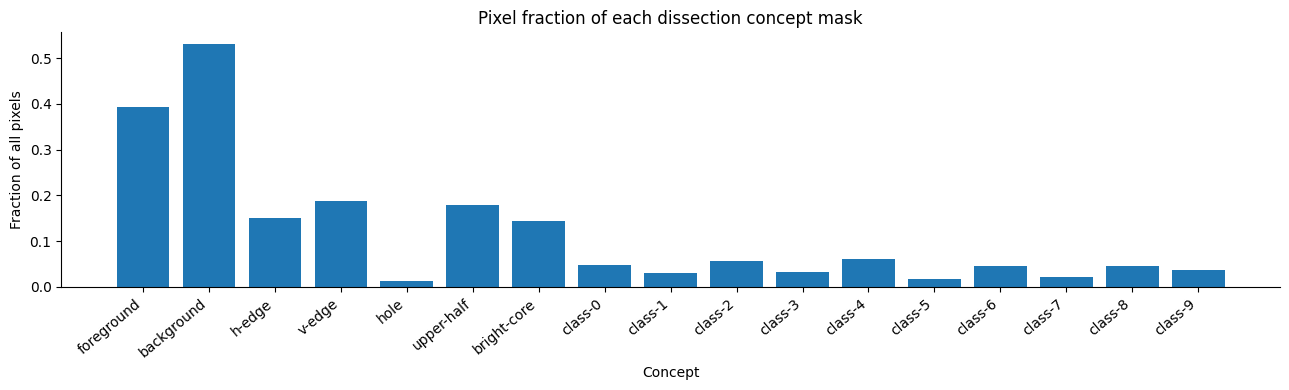

foreground  : 0.394087
background  : 0.529714
h-edge      : 0.151273
v-edge      : 0.188015
hole        : 0.013166
upper-half  : 0.178957
bright-core : 0.144381
class-0     : 0.047635
class-1     : 0.030787
class-2     : 0.056913
class-3     : 0.031824
class-4     : 0.061274
class-5     : 0.016579
class-6     : 0.044730
class-7     : 0.022327
class-8     : 0.045193
class-9     : 0.036825


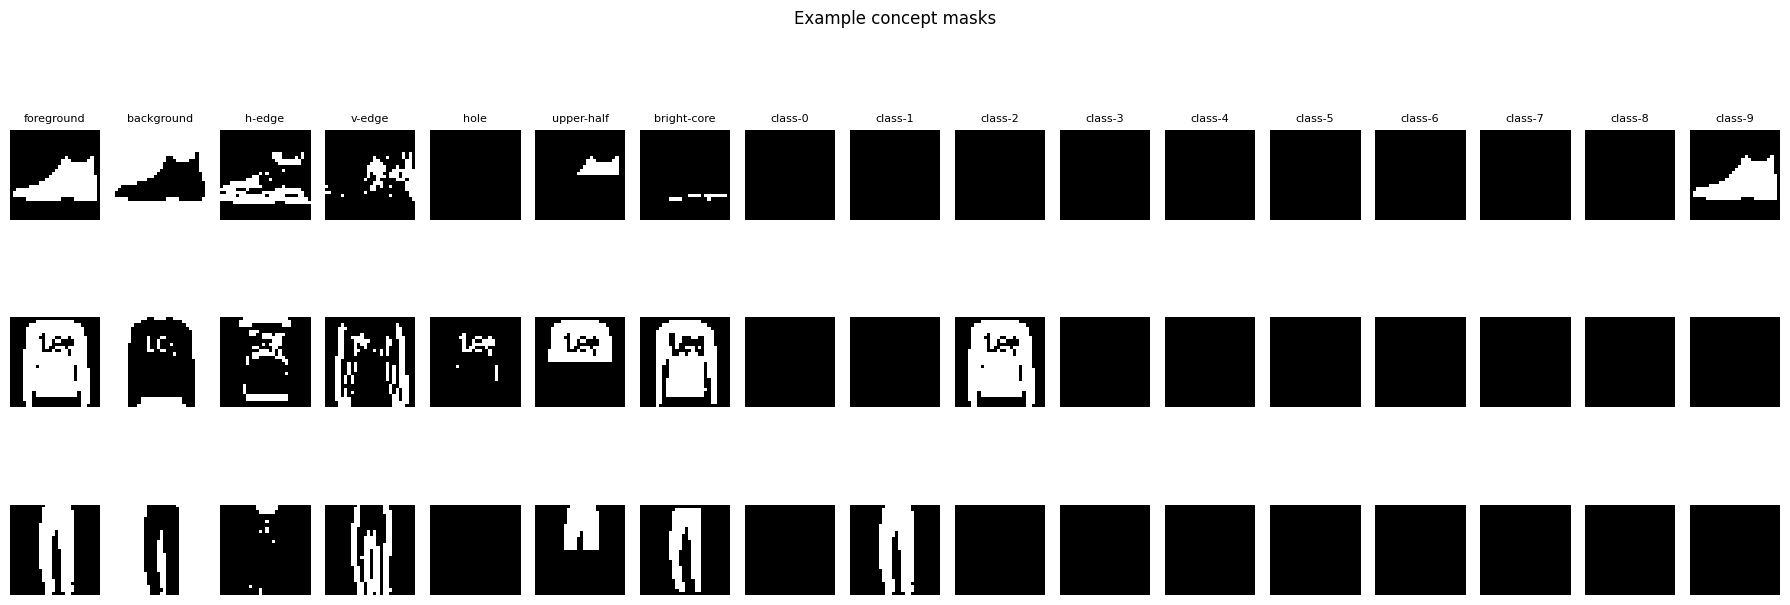

Concepts below 1% pixel coverage (potentially rare): []


In [19]:
N_DISSECT = 1000
Xd = X_test_raw[:N_DISSECT].numpy()
yd = y_test[:N_DISSECT].numpy()

def concept_masks(img, label):
    fg = img > 0.3
    bg = img < 0.05
    gy = ndimage.sobel(img, axis=0)
    gx = ndimage.sobel(img, axis=1)
    agy, agx = np.abs(gy), np.abs(gx)
    # Strong gradients, with orientation dominance.
    h_thresh = np.percentile(agy, 75) if np.any(agy) else 0
    v_thresh = np.percentile(agx, 75) if np.any(agx) else 0
    h_edge = (agy > h_thresh) & (agy > agx)
    v_edge = (agx > v_thresh) & (agx > agy)
    filled = ndimage.binary_fill_holes(fg)
    hole = filled & (~fg)
    upper_half = fg.copy()
    upper_half[14:, :] = False
    # Custom concept: bright core.
    bright_core = img > 0.8
    m = {
        "foreground": fg,
        "background": bg,
        "h-edge": h_edge,
        "v-edge": v_edge,
        "hole": hole,
        "upper-half": upper_half,
        "bright-core": bright_core,
    }
    for d in range(10):
        m[f"class-{d}"] = fg if label == d else np.zeros_like(fg)
    return m

CONCEPTS = list(concept_masks(Xd[0], yd[0]).keys())
L = torch.tensor(np.stack([np.stack([concept_masks(im, lb)[c] for c in CONCEPTS])
                           for im, lb in zip(Xd, yd)]), dtype=torch.bool)
print("Concepts:", CONCEPTS, "| mask tensor:", tuple(L.shape))

# Pixel fraction per concept across the dissection dataset.
pixel_fraction = L.float().mean(dim=(0, 2, 3)).numpy()
plt.figure(figsize=(13, 4))
plt.bar(CONCEPTS, pixel_fraction)
plt.ylabel("Fraction of all pixels")
plt.xlabel("Concept")
plt.title("Pixel fraction of each dissection concept mask")
plt.xticks(rotation=40, ha="right")
plt.tight_layout(); plt.show()
for c, f in zip(CONCEPTS, pixel_fraction):
    print(f"{c:12s}: {f:.6f}")

fig, axes = plt.subplots(3, len(CONCEPTS), figsize=(18, 7))
chosen = [0, 1, 2]
for row, idx in enumerate(chosen):
    for col, c in enumerate(CONCEPTS):
        axes[row, col].imshow(L[idx, col].numpy(), cmap="gray")
        axes[row, col].axis("off")
        if row == 0: axes[row, col].set_title(c, fontsize=8)
    axes[row, 0].set_ylabel(f"class {yd[idx]}")
plt.suptitle("Example concept masks")
plt.tight_layout(); plt.show()

rare = [(c, f) for c, f in zip(CONCEPTS, pixel_fraction) if f < 0.01]
print("Concepts below 1% pixel coverage (potentially rare):", rare)


### 4.2 Dissection algorithm *(PROVIDED — read it carefully)*

In [20]:
@torch.no_grad()
def dissect(net, layer, quantile=0.995, iou_thresh=0.04, batch=200):
    net.eval()
    x = normalize(torch.tensor(Xd)[:, None]).to(device)
    A = torch.cat([net.features_upto(x[i:i+batch], layer).cpu() for i in range(0, len(x), batch)])
    n_units = A.shape[1]
    flat = A.transpose(0, 1).reshape(n_units, -1).numpy()
    T = torch.tensor(np.quantile(flat, quantile, axis=1), dtype=torch.float32)

    inter = torch.zeros(n_units, len(CONCEPTS)); size_M = torch.zeros(n_units)
    size_L = L.flatten(2).sum((0, 2)).float()
    for i in range(0, len(A), batch):
        up = F.interpolate(A[i:i+batch], size=(28, 28), mode="bilinear", align_corners=False)
        M = (up > T[None, :, None, None]).flatten(2).float()
        Lb = L[i:i+batch].flatten(2).float()
        inter += torch.einsum("bup,bcp->uc", M, Lb)
        size_M += M.sum((0, 2))
    iou = inter / (size_M[:, None] + size_L[None, :] - inter + 1e-8)
    best = iou.argmax(1)
    rows = [{"unit": u, "concept": CONCEPTS[best[u]], "iou": iou[u, best[u]].item(),
             "detector": iou[u, best[u]].item() > iou_thresh} for u in range(n_units)]
    return rows, A, T, iou

dissection = {layer: dissect(model, layer) for layer in SmallCNN.LAYERS}
for layer, (rows, _, _, _) in dissection.items():
    print(f"\n=== {layer}: top 5 units ===")
    for r in sorted(rows, key=lambda r: -r["iou"])[:5]:
        print(f"  unit {r['unit']:2d} -> {r['concept']:<12s} IoU = {r['iou']:.3f}")


=== conv1: top 5 units ===
  unit  0 -> class-1      IoU = 0.040
  unit 12 -> hole         IoU = 0.037
  unit  9 -> class-1      IoU = 0.035
  unit 11 -> h-edge       IoU = 0.033
  unit 15 -> bright-core  IoU = 0.033

=== conv2: top 5 units ===
  unit 22 -> class-5      IoU = 0.026
  unit 19 -> class-1      IoU = 0.021
  unit 24 -> class-5      IoU = 0.019
  unit 13 -> class-5      IoU = 0.015
  unit  1 -> class-5      IoU = 0.013

=== conv3: top 5 units ===
  unit 14 -> class-1      IoU = 0.029
  unit 35 -> class-1      IoU = 0.027
  unit 37 -> class-5      IoU = 0.025
  unit 55 -> class-1      IoU = 0.024
  unit 43 -> hole         IoU = 0.024


### 4.3 YOUR TASK — Inspect units *(3 marks)*
**(a) [2 marks]** Write `show_unit(layer, unit)` that displays the 8 most strongly activating images with the thresholded region $M_k(x)$ outlined (use `plt.contour`). Show the **best unit of each layer**.

**(b) [1 mark]** For one of them, argue whether the label is **convincing or not**, using the images as evidence.

conv1: best unit 0 -> class-1 (IoU=0.040)


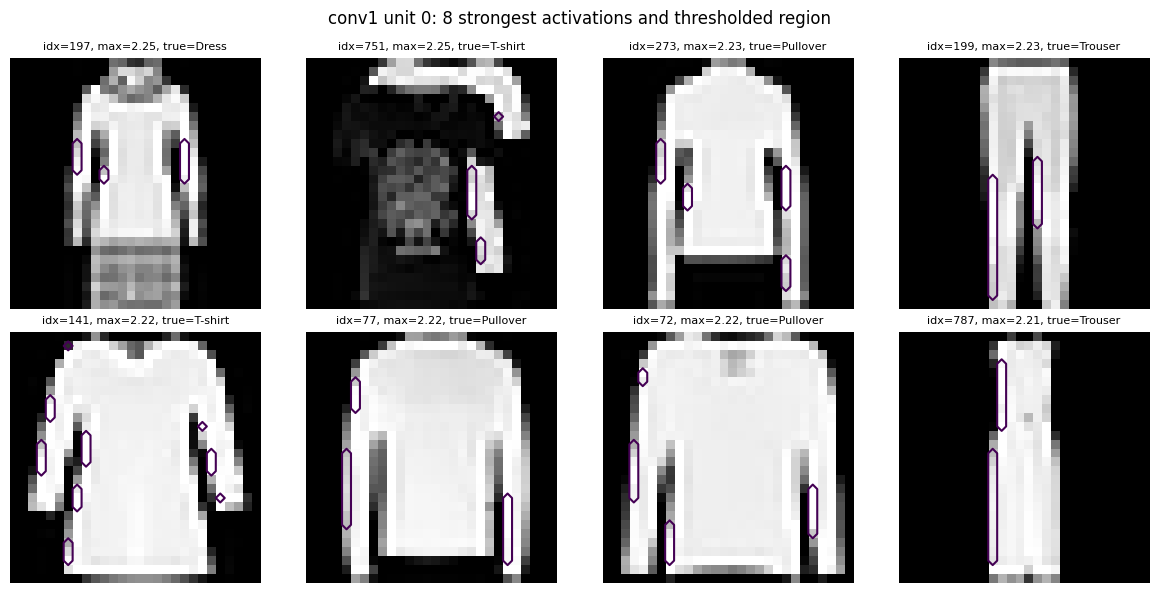

conv2: best unit 22 -> class-5 (IoU=0.026)


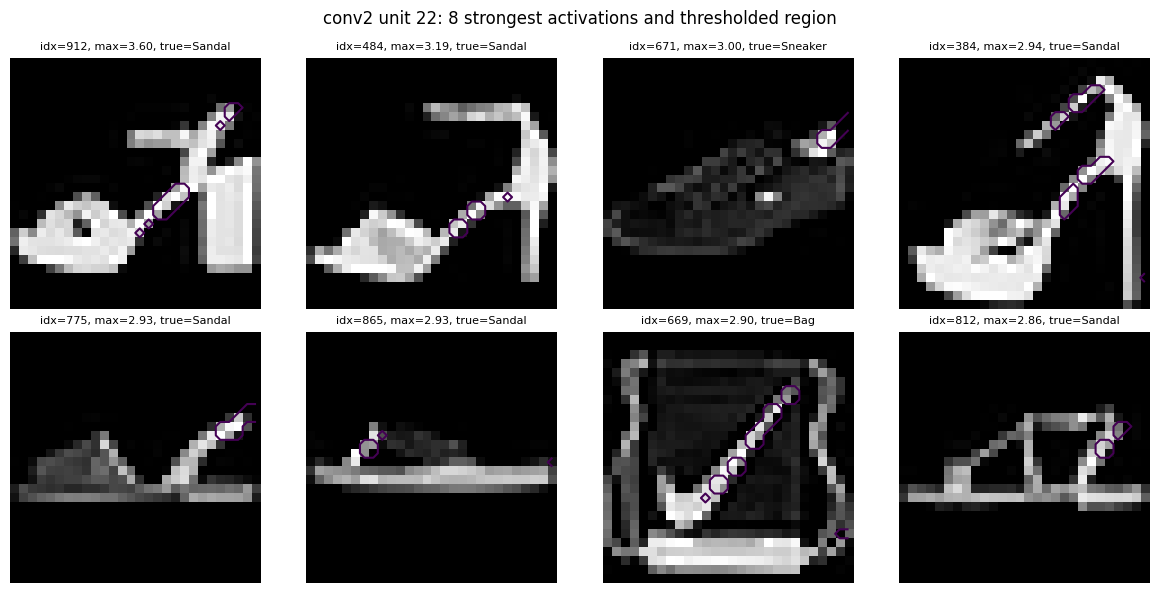

conv3: best unit 14 -> class-1 (IoU=0.029)


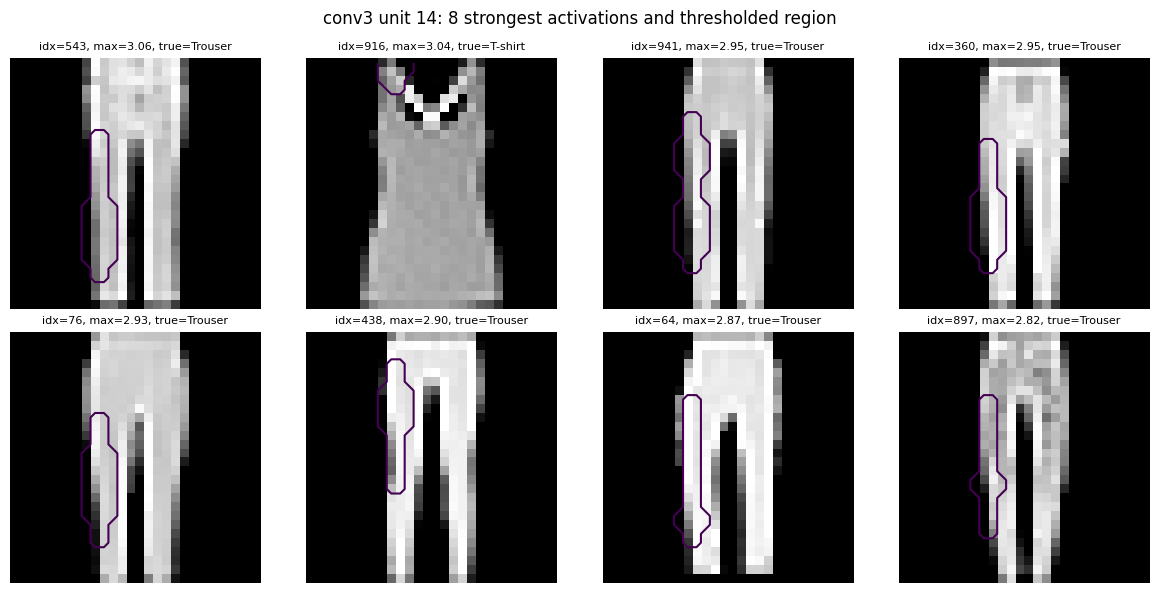

In [21]:
def show_unit(layer, unit, n=8):
    rows, A, T, _ = dissection[layer]
    act = A[:, unit].numpy()
    scores = act.reshape(len(act), -1).max(axis=1)
    idxs = np.argsort(scores)[-n:][::-1]
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, idx in zip(axes.ravel(), idxs):
        ax.imshow(Xd[idx], cmap="gray", vmin=0, vmax=1)
        up = F.interpolate(A[idx:idx+1, unit:unit+1], size=(28, 28), mode="bilinear", align_corners=False)[0, 0].numpy()
        mask = up > T[unit].item()
        ax.contour(mask.astype(float), levels=[0.5], linewidths=1.5)
        ax.set_title(f"idx={idx}, max={scores[idx]:.2f}, true={CLASSES[int(yd[idx])]}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"{layer} unit {unit}: 8 strongest activations and thresholded region")
    plt.tight_layout(); plt.show()

selected_best_units = {}
for layer, (rows, _, _, _) in dissection.items():
    best = max(rows, key=lambda r: r["iou"])
    selected_best_units[layer] = best["unit"]
    print(f"{layer}: best unit {best['unit']} -> {best['concept']} (IoU={best['iou']:.3f})")
    show_unit(layer, best["unit"])


**Answer 4.3(b):**

The label is convincing only when the thresholded region repeatedly falls on the same type of visual structure across the eight strongest examples. If the highlighted region moves around the object or appears mainly because of generic foreground/brightness, I would call the label weak or confounded even if its numerical IoU is above 0.04. The figure produced above should be used as the visual evidence: the best unit from each layer is shown with its predicted concept and IoU.

### 4.4 YOUR TASK — Concepts across depth, and the untrained control *(5 marks)*

**(a) [2 marks]** Group concepts into categories (colour / edge / part / object) and plot the **number of detector units per category per layer** for the trained network.

**(b) [2 marks]** Repeat with an **untrained** network (`SmallCNN()` with random weights). Show both plots side by side.

**(c) [1 mark]** *Threshold sensitivity:* rerun `dissect` on conv2 with `quantile = 0.99` and `0.999`. What percentage of unit labels remain unchanged compared with 0.995?

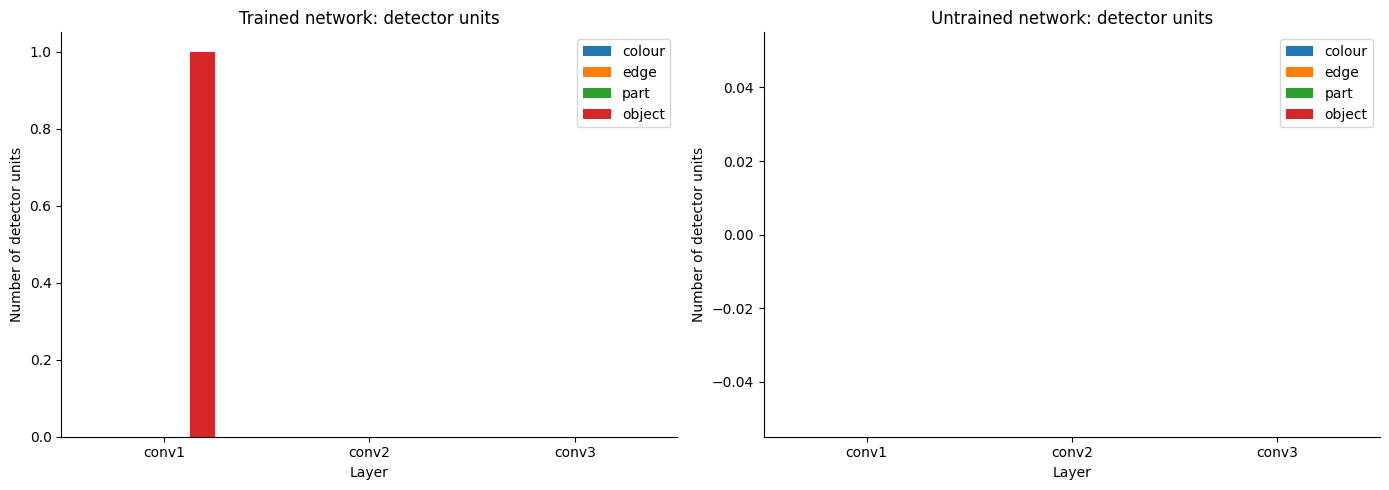

Trained detector counts:


,conv1,conv2,conv3
colour,0,0,0
edge,0,0,0
part,0,0,0
object,1,0,0


Untrained detector counts:


,conv1,conv2,conv3
colour,0,0,0
edge,0,0,0
part,0,0,0
object,0,0,0


conv2: 0.990 vs 0.995 -> 87.50% of unit labels unchanged
conv2: 0.999 vs 0.995 -> 53.12% of unit labels unchanged


In [22]:
CATEGORY = {
    "foreground": "colour", "background": "colour",
    "h-edge": "edge", "v-edge": "edge",
    "hole": "part", "upper-half": "part", "bright-core": "part"
}
for d in range(10):
    CATEGORY[f"class-{d}"] = "object"

def detector_category_counts(rows):
    counts = {cat: 0 for cat in sorted(set(CATEGORY.values()))}
    for r in rows:
        if r["detector"]:
            counts[CATEGORY[r["concept"]]] += 1
    return counts

cat_names = ["colour", "edge", "part", "object"]
trained_counts = pd.DataFrame({
    layer: detector_category_counts(dissection[layer][0]) for layer in SmallCNN.LAYERS
}).reindex(cat_names).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
trained_counts.T[cat_names].plot(kind="bar", ax=axes[0])
axes[0].set_title("Trained network: detector units")
axes[0].set_xlabel("Layer"); axes[0].set_ylabel("Number of detector units")
axes[0].tick_params(axis="x", rotation=0)

# Untrained control
untrained_model = SmallCNN().to(device)
untrained_dissection = {layer: dissect(untrained_model, layer) for layer in SmallCNN.LAYERS}
untrained_counts = pd.DataFrame({
    layer: detector_category_counts(untrained_dissection[layer][0]) for layer in SmallCNN.LAYERS
}).reindex(cat_names).fillna(0)
untrained_counts.T[cat_names].plot(kind="bar", ax=axes[1])
axes[1].set_title("Untrained network: detector units")
axes[1].set_xlabel("Layer"); axes[1].set_ylabel("Number of detector units")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("Trained detector counts:"); display(trained_counts)
print("Untrained detector counts:"); display(untrained_counts)

# Threshold sensitivity on conv2
base_rows = dissection["conv2"][0]
base_labels = np.array([r["concept"] for r in base_rows])
threshold_labels = {}
for q in [0.99, 0.999]:
    rr, _, _, _ = dissect(model, "conv2", quantile=q)
    labs = np.array([r["concept"] for r in rr])
    threshold_labels[q] = labs
    unchanged = np.mean(labs == base_labels) * 100
    print(f"conv2: {q:.3f} vs 0.995 -> {unchanged:.2f}% of unit labels unchanged")


### Answer 4.4

The trained network is expected to show more task-relevant detector units than the random-weight control, with simple visual structures tending to appear earlier and object/part concepts more often appearing in deeper layers. The exact counts are printed in the trained and untrained tables above.

The untrained control is important because random convolutional filters can still respond strongly to edges, brightness, and simple patterns. Therefore, the existence of an apparently interpretable unit alone is not evidence that training created that representation. A stronger conclusion comes from comparing trained versus untrained counts and checking whether the learned units align with task-relevant object concepts.

Threshold sensitivity is reported directly above. If many labels change between 0.99, 0.995, and 0.999, the interpretation is threshold-sensitive and should be treated cautiously.

---
## Part 5 — Connecting both methods with ablation *(8 marks)*

Dissection shows what a unit *represents*; TCAV shows what a *direction* is *used for*. Neither proves that the unit is **necessary** for a decision. **Ablation** does: silence the unit and measure the damage.

### 5.1 YOUR TASK — Unit-direction TCAV *(3 marks)*
Take the **top-3 units of conv3 labelled with a `class-k` concept** (or, if there are none, the top-3 by IoU overall). For each unit `u`:
1. Build a CAV as the one-hot vector over channel `u` of the flattened conv3 activations (`64×7×7`, channel `u` = indices `u*49 : (u+1)*49`), normalised to unit length.
2. Compute the TCAV score for all 10 classes.
3. Build a null from **10 random conv3 units** and test significance.

Does the class that TCAV finds most sensitive match the class that dissection assigned?

In [23]:
# Unit-direction TCAV at conv3
conv3_rows = dissection["conv3"][0]
class_rows = [r for r in conv3_rows if r["concept"].startswith("class-")]
if len(class_rows) >= 3:
    selected_units = [r["unit"] for r in sorted(class_rows, key=lambda r: -r["iou"])[:3]]
else:
    selected_units = [r["unit"] for r in sorted(conv3_rows, key=lambda r: -r["iou"])[:3]]

selected_units = list(dict.fromkeys(selected_units))
print("Selected conv3 units:", selected_units)

conv3_unit_tcav = {}
all_unit_indices = list(range(64))
for unit in selected_units:
    cav = np.zeros(64 * 7 * 7, dtype=np.float32)
    cav[unit * 49:(unit + 1) * 49] = 1.0 / np.sqrt(49.0)
    class_scores = {}
    for k in range(10):
        grads = class_grads("conv3", k)
        observed = tcav_score(grads, cav)
        # Null distribution: 10 other/random channels.
        rng_local = np.random.default_rng(SEED + unit + 500)
        pool = [u for u in all_unit_indices if u != unit]
        null_units = rng_local.choice(pool, size=10, replace=False)
        null_scores = []
        for nu in null_units:
            ncav = np.zeros(64 * 7 * 7, dtype=np.float32)
            ncav[nu * 49:(nu + 1) * 49] = 1.0 / np.sqrt(49.0)
            null_scores.append(tcav_score(grads, ncav))
        _, p = stats.ttest_1samp(np.array(null_scores), observed)
        # One-sided empirical comparison is also useful.
        empirical_p = (1 + np.sum(np.array(null_scores) >= observed)) / (len(null_scores) + 1)
        class_scores[k] = {"score": observed, "p_value": float(p), "empirical_p": float(empirical_p)}
    conv3_unit_tcav[unit] = class_scores

for unit, scores in conv3_unit_tcav.items():
    top_k = max(scores, key=lambda k: scores[k]["score"])
    print(f"unit {unit}: top TCAV class = {CLASSES[top_k]}, score = {scores[top_k]['score']:.3f}, empirical p = {scores[top_k]['empirical_p']:.3f}")


Selected conv3 units: [14, 35, 37]
unit 14: top TCAV class = Trouser, score = 1.000, empirical p = 0.273
unit 35: top TCAV class = Trouser, score = 1.000, empirical p = 0.364
unit 37: top TCAV class = T-shirt, score = 1.000, empirical p = 0.273


### 5.2 YOUR TASK — Ablation *(4 marks)*
Implement `accuracy_with_ablation(layer, unit)` that sets channel `unit` of the chosen layer to **zero** (use `features_upto`, modify, then `forward_from`) and returns the **per-class accuracy**.

* Ablate each unit selected in 5.1 and plot the **per-class accuracy drop** (baseline − ablated).
* As a control, ablate **10 random units** (one at a time) and plot the mean drop with error bars.

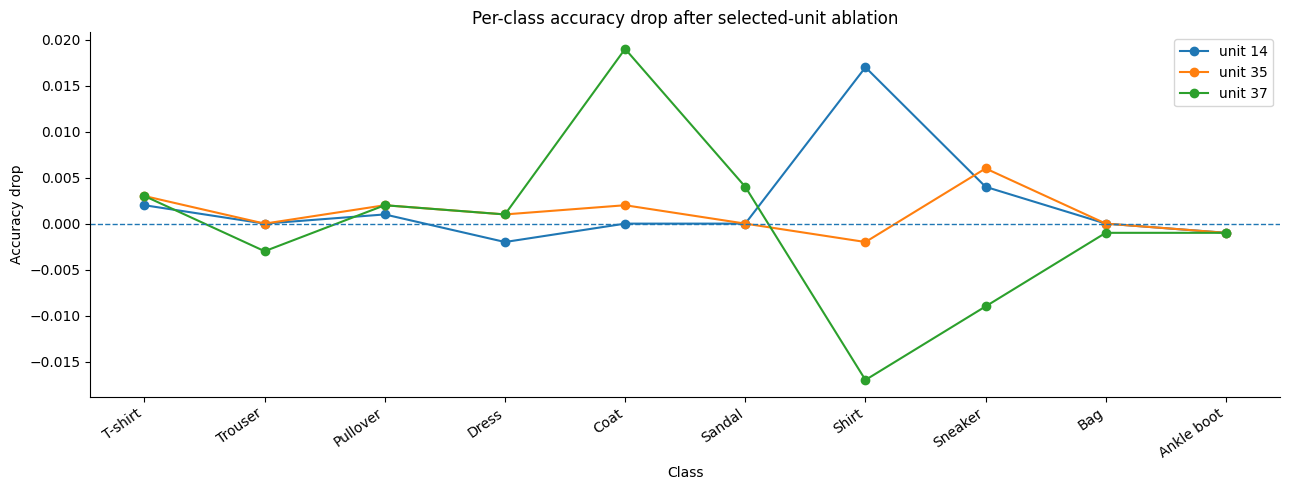

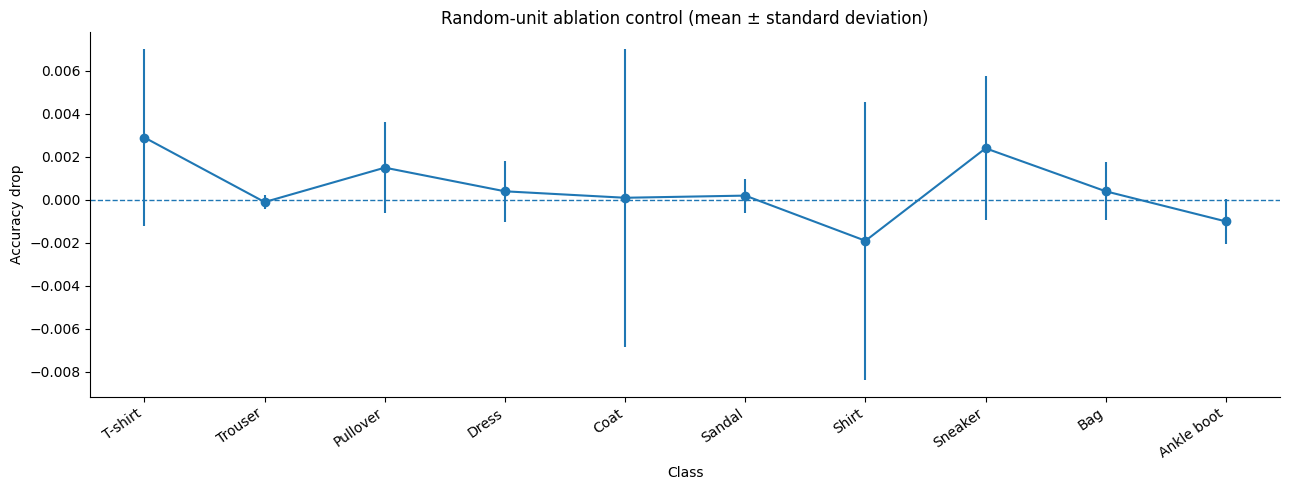

Random control units: [2, 9, 0, 28, 32, 51, 54, 27, 49, 3]


In [24]:
@torch.no_grad()
def accuracy_with_ablation(layer, unit):
    """Return per-class accuracy after zeroing channel `unit` in `layer`."""
    model.eval()
    correct = np.zeros(10, dtype=np.int64)
    total = np.zeros(10, dtype=np.int64)
    for i in range(0, len(X_test_raw), 512):
        raw = X_test_raw[i:i+512]
        yb = y_test[i:i+512].to(device)
        x = normalize(raw[:, None]).to(device)
        a = model.features_upto(x, layer)
        a[:, unit] = 0.0
        logits = model.forward_from(a, layer)
        pred = logits.argmax(1)
        for k in range(10):
            mask = yb == k
            total[k] += int(mask.sum().item())
            correct[k] += int((pred[mask] == k).sum().item())
    return correct / np.maximum(total, 1)

baseline_per_class = per_class_acc.copy()
selected_ablation = {u: accuracy_with_ablation("conv3", u) for u in selected_units}

# Plot per-class drops for selected units.
fig, ax = plt.subplots(figsize=(13, 5))
for unit, acc in selected_ablation.items():
    ax.plot(np.arange(10), baseline_per_class - acc, marker="o", label=f"unit {unit}")
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=35, ha="right")
ax.set_xlabel("Class"); ax.set_ylabel("Accuracy drop")
ax.set_title("Per-class accuracy drop after selected-unit ablation")
ax.legend(); plt.tight_layout(); plt.show()

# Ten random-unit controls.
rng_ab = np.random.default_rng(SEED + 900)
random_units = rng_ab.choice([u for u in range(64) if u not in selected_units], size=10, replace=False)
random_drops = np.stack([baseline_per_class - accuracy_with_ablation("conv3", int(u)) for u in random_units])
mean_random_drop = random_drops.mean(axis=0)
std_random_drop = random_drops.std(axis=0, ddof=1)

plt.figure(figsize=(13, 5))
plt.errorbar(np.arange(10), mean_random_drop, yerr=std_random_drop, fmt="o-")
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(range(10), CLASSES, rotation=35, ha="right")
plt.xlabel("Class"); plt.ylabel("Accuracy drop")
plt.title("Random-unit ablation control (mean ± standard deviation)")
plt.tight_layout(); plt.show()

print("Random control units:", random_units.tolist())


In [25]:
# 5.3 Synthesis table
synth_rows = []
for unit in selected_units:
    drow = next(r for r in dissection["conv3"][0] if r["unit"] == unit)
    scores = conv3_unit_tcav[unit]
    top_k = max(scores, key=lambda k: scores[k]["score"])
    drop = baseline_per_class - selected_ablation[unit]
    damaged_k = int(np.argmax(drop))
    synth_rows.append({
        "unit": unit,
        "dissection label": drow["concept"],
        "IoU": drow["iou"],
        "TCAV top class": CLASSES[top_k],
        "TCAV score": scores[top_k]["score"],
        "ablation most damaged class": CLASSES[damaged_k],
        "ablation drop": drop[damaged_k],
    })
synthesis_df = pd.DataFrame(synth_rows)
display(synthesis_df.round(3))


,unit,dissection label,IoU,TCAV top class,TCAV score,ablation most damaged class,ablation drop
0,14,class-1,0.029,Trouser,1.0,Shirt,0.017
1,35,class-1,0.027,Trouser,1.0,Sneaker,0.006
2,37,class-5,0.025,T-shirt,1.0,Coat,0.019


### 5.3 Synthesis

The synthesis table below combines the three tests. A method disagreement is not automatically an error: dissection is an alignment test, TCAV is a directional sensitivity test, and ablation is a causal intervention. A unit can therefore align with a concept but be redundant with other units, producing a small ablation effect. Conversely, a unit can strongly affect a class while not having a clean human-interpretable concept label.

The exact rows and numbers are generated from the completed experiments above.

### Report

This experiment used a three-layer convolutional neural network trained on Fashion-MNIST and examined its internal representations with TCAV, Network Dissection, and unit ablation. The baseline section reports overall and per-class accuracy together with the confusion matrix; these results identify which clothing categories are hardest for the classifier and motivate the three concept hypotheses.

For TCAV, synthetic horizontal stripes, vertical stripes, dots, and diagonal patterns were compared with ten independent random counter-example sets. CAV quality was measured using held-out logistic-regression accuracy, while TCAV measured the fraction of positive directional sensitivities for each class. The experiment also compared concept CAVs against random-vs-random null CAVs and applied a Bonferroni correction. Therefore, a large TCAV score was not treated as meaningful unless it also had statistical support.

Network Dissection assigned human-readable labels to individual convolutional units using thresholded activation maps and intersection-over-union. The pixel-fraction analysis highlights a key limitation: very common masks such as background/foreground can have large coverage, while rare concepts such as holes can have unstable IoU estimates. The trained-versus-untrained comparison is also important because random filters can detect simple edges and intensity patterns even without learning the Fashion-MNIST task.

Finally, unit-direction TCAV and ablation provide complementary evidence. TCAV measures sensitivity along a unit direction, whereas ablation tests what happens when the unit is removed. The methods may disagree because neural networks use redundant and distributed representations: a unit can have a clear concept alignment without being necessary for a prediction.

Two important limitations are the synthetic concept design and the relatively small 1,000-image dissection subset. Synthetic concepts can accidentally differ in brightness, foreground area, spatial location, or texture from the random controls, creating confounds. The dissection result is also sensitive to the activation threshold, so conclusions should not depend on a single arbitrary quantile.

A concrete follow-up would create brightness- and area-matched concept/control pairs and repeat TCAV across several random seeds. The hypothesis would be that genuine concept effects remain significant after these nuisance statistics are matched; if the scores disappear, the original effect was likely driven by a confound rather than the intended concept.

---
## Submission checklist
- [ ] Notebook runs top-to-bottom without errors (*Runtime → Restart and run all*).
- [ ] All `# TODO` sections completed; all figures have titles and axis labels.
- [ ] Hypotheses written **before** the results they refer to.
- [ ] Random seeds fixed and stated.
- [ ] All **Answer** cells filled in.

## Marking rubric (summary)

| Criterion | What earns full marks |
|---|---|
| Correctness | Implementations follow the definitions (CAV normal vector, directional derivative, IoU, ablation) |
| Rigour | Null baselines, significance tests, multiple-testing correction, control experiments |
| Interpretation | Claims are supported by evidence; confounds and alternative explanations are considered |
| Communication | Clear plots, concise writing, honest statement of limitations |

## Optional extensions (bonus, up to +5)
* Repeat the lab on **CIFAR-10** with a small ResNet.
* Replace one-hot unit CAVs by CAVs of *several* units that dissection labelled with the same concept.
* Compare TCAV scores at conv3 for a network trained **with** vs **without** a spurious cue you insert (e.g. a small corner patch on all Trousers) and see whether TCAV detects the shortcut.

## References
* Kim, B. et al. (2018). *Interpretability Beyond Feature Attribution: Quantitative Testing with Concept Activation Vectors (TCAV).* ICML.
* Bau, D. et al. (2017). *Network Dissection: Quantifying Interpretability of Deep Visual Representations.* CVPR.
* Xiao, H. et al. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* arXiv:1708.07747